## 1. Entorno y archivos

In [1]:
from pathlib import Path
from collections import Counter
from textwrap import fill
from matplotlib.patches import Patch
import hashlib
import json
import re
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

FOLDER = "cfpb_complaints_2023-06-01_2024-05-31"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / FOLDER).is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abre el notebook desde la raíz del proyecto o EDA/, con el CSV extraído en su carpeta original.")
DATA = ROOT / FOLDER / f"{FOLDER}.csv"
PROVENANCE = ROOT / FOLDER / "PROCEDENCIA.txt"
ZIP_HASH = ROOT / f"{FOLDER}.zip.sha256"

## 2. Lectura de datos

In [2]:
missing = Counter()
values = {}
parts = []
sample = None
zip_values = set()

for chunk in pd.read_csv(DATA, dtype=str, chunksize=25_000):
    if sample is None:
        columns = chunk.columns.tolist()
        sample = chunk.head(5).copy()
        sample["Consumer complaint narrative"] = sample["Consumer complaint narrative"].str.slice(0, 240)
    missing.update(chunk.isna().sum().to_dict())
    zip_values.update(chunk["ZIP code"].dropna())
    for col in columns:
        if col not in ["Consumer complaint narrative", "Complaint ID", "ZIP code"]:
            values.setdefault(col, Counter()).update(chunk[col].dropna())
    text = chunk["Consumer complaint narrative"].fillna("")
    normalized = text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    small = chunk.drop(columns=["Consumer complaint narrative", "Company public response", "Tags", "ZIP code"]).copy()
    small["characters"] = text.str.len()
    small["words"] = text.str.split().str.len()
    small["text_hash"] = pd.util.hash_pandas_object(text, index=False).to_numpy()
    small["normalized_hash"] = pd.util.hash_pandas_object(normalized, index=False).to_numpy()
    small["blank_text"] = text.str.strip().eq("")
    parts.append(small)

df = pd.concat(parts, ignore_index=True)
del parts, chunk, small, text, normalized
df["date"] = pd.to_datetime(df["Date received"], errors="raise")
df["month"] = df["date"].dt.strftime("%Y-%m")
df["lag_days"] = (pd.to_datetime(df["Date sent to company"], errors="raise") - df["date"]).dt.days
n = len(df)
monthly = pd.crosstab(df["month"], df["Product"])
products = df["Product"].value_counts()
print(f"Leídas {n:,} filas, {len(columns)} columnas y {len(products)} etiquetas originales.")
sample.head(2)

Leídas 582,489 filas, 16 columnas y 14 etiquetas originales.


,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2023-06-01,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,On XX/XX/2023 I sent a letter regarding inaccu...,NaN,"EQUIFAX, INC.",TX,770XX,NaN,Web,2023-06-01,Closed with explanation,Yes,7050835
1,2023-06-01,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,"To provide some context, I have thoroughly rev...",NaN,"EQUIFAX, INC.",CA,92620,NaN,Web,2023-06-01,Closed with non-monetary relief,Yes,7050841


## 3. Nulos y valores únicos

In [3]:
unique_counts = {col: len(counts) for col, counts in values.items()}
unique_counts.update({
    "Consumer complaint narrative": int(df["text_hash"].nunique()),
    "Complaint ID": int(df["Complaint ID"].nunique()),
    "ZIP code": len(zip_values),
})
# La unicidad de las narrativas usa el mismo hash de 64 bits que el análisis de duplicados.
quality = pd.DataFrame({
    "% de nulos": [100 * missing[col] / n for col in columns],
    "Valores únicos": [unique_counts[col] for col in columns],
}, index=pd.Index(columns, name="Columna"))
assert len(quality) == 16 and quality["Valores únicos"].notna().all()
display(quality.round({"% de nulos": 2}))

,% de nulos,Valores únicos
Columna,,
Date received,0.00,366
Product,0.00,14
Sub-product,0.00,58
Issue,0.00,91
Sub-issue,3.35,210
Consumer complaint narrative,0.00,377462
Company public response,42.78,10
Company,0.00,2902
State,0.33,60


## 4. Distribución de productos y subproductos

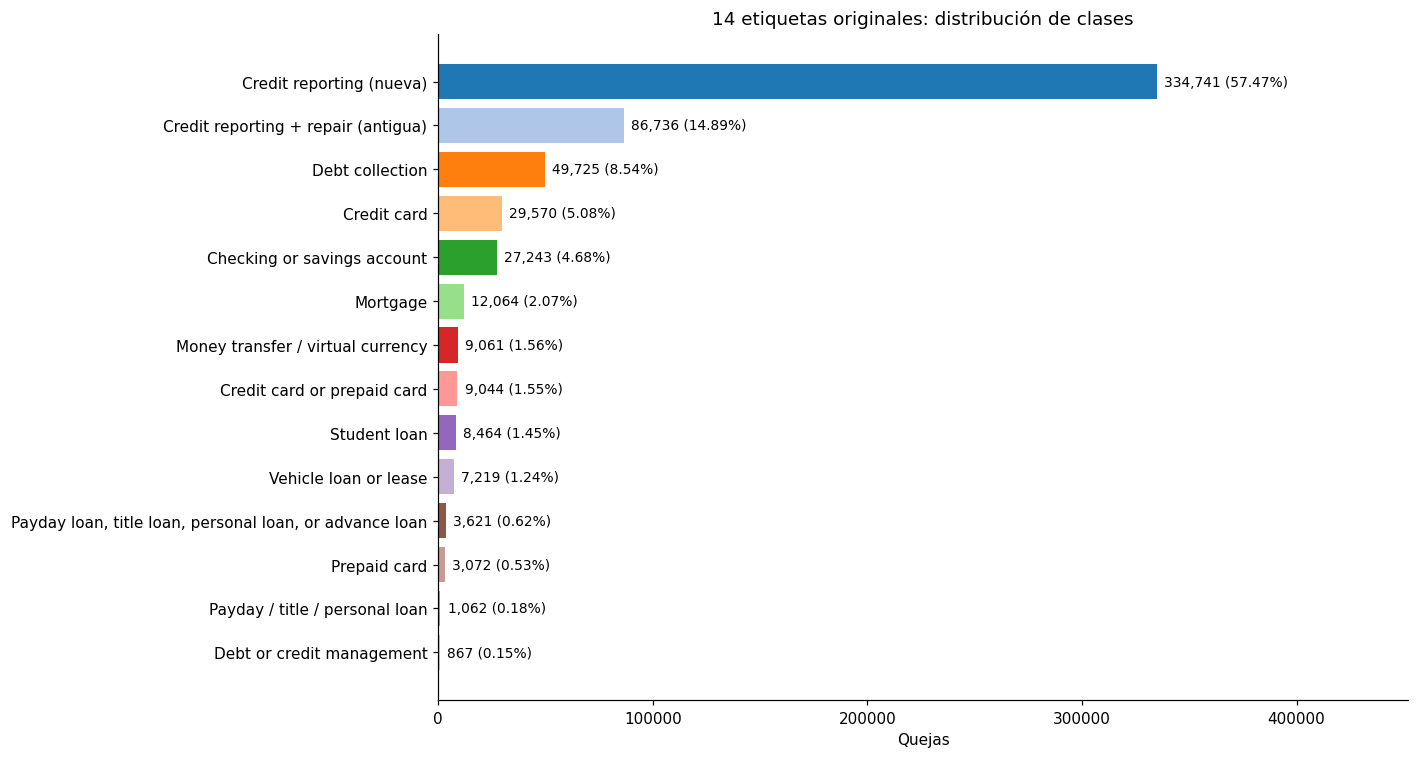

In [4]:
product_table = df.groupby("Product").agg(
    Quejas=("Product", "size"), Primera_fecha=("Date received", "min"),
    Ultima_fecha=("Date received", "max"), Mediana_caracteres=("characters", "median"),
    Subproductos=("Sub-product", "nunique"))
product_table["Porcentaje"] = 100 * product_table.Quejas / n
product_table = product_table.sort_values("Quejas", ascending=False)

short = {p: p.replace("Credit reporting, credit repair services, or other personal consumer reports", "Credit reporting + repair (antigua)")
            .replace("Credit reporting or other personal consumer reports", "Credit reporting (nueva)")
            .replace("Money transfer, virtual currency, or money service", "Money transfer / virtual currency")
            .replace("Payday loan, title loan, or personal loan", "Payday / title / personal loan")
         for p in products.index}
product_colors = {p: plt.get_cmap("tab20")(i) for i, p in enumerate(products.index)}
fig, ax = plt.subplots(figsize=(13, 7))
ordered = products.iloc[::-1]
ax.barh([short[p] for p in ordered.index], ordered.values, color=[product_colors[p] for p in ordered.index])
for i, value in enumerate(ordered):
    ax.text(value + products.max() * .01, i, f"{value:,} ({100*value/n:.2f}%)", va="center", fontsize=9)
ax.set(xlim=(0, products.max()*1.35), xlabel="Quejas", title="14 etiquetas originales: distribución de clases")
plt.tight_layout(); plt.show()

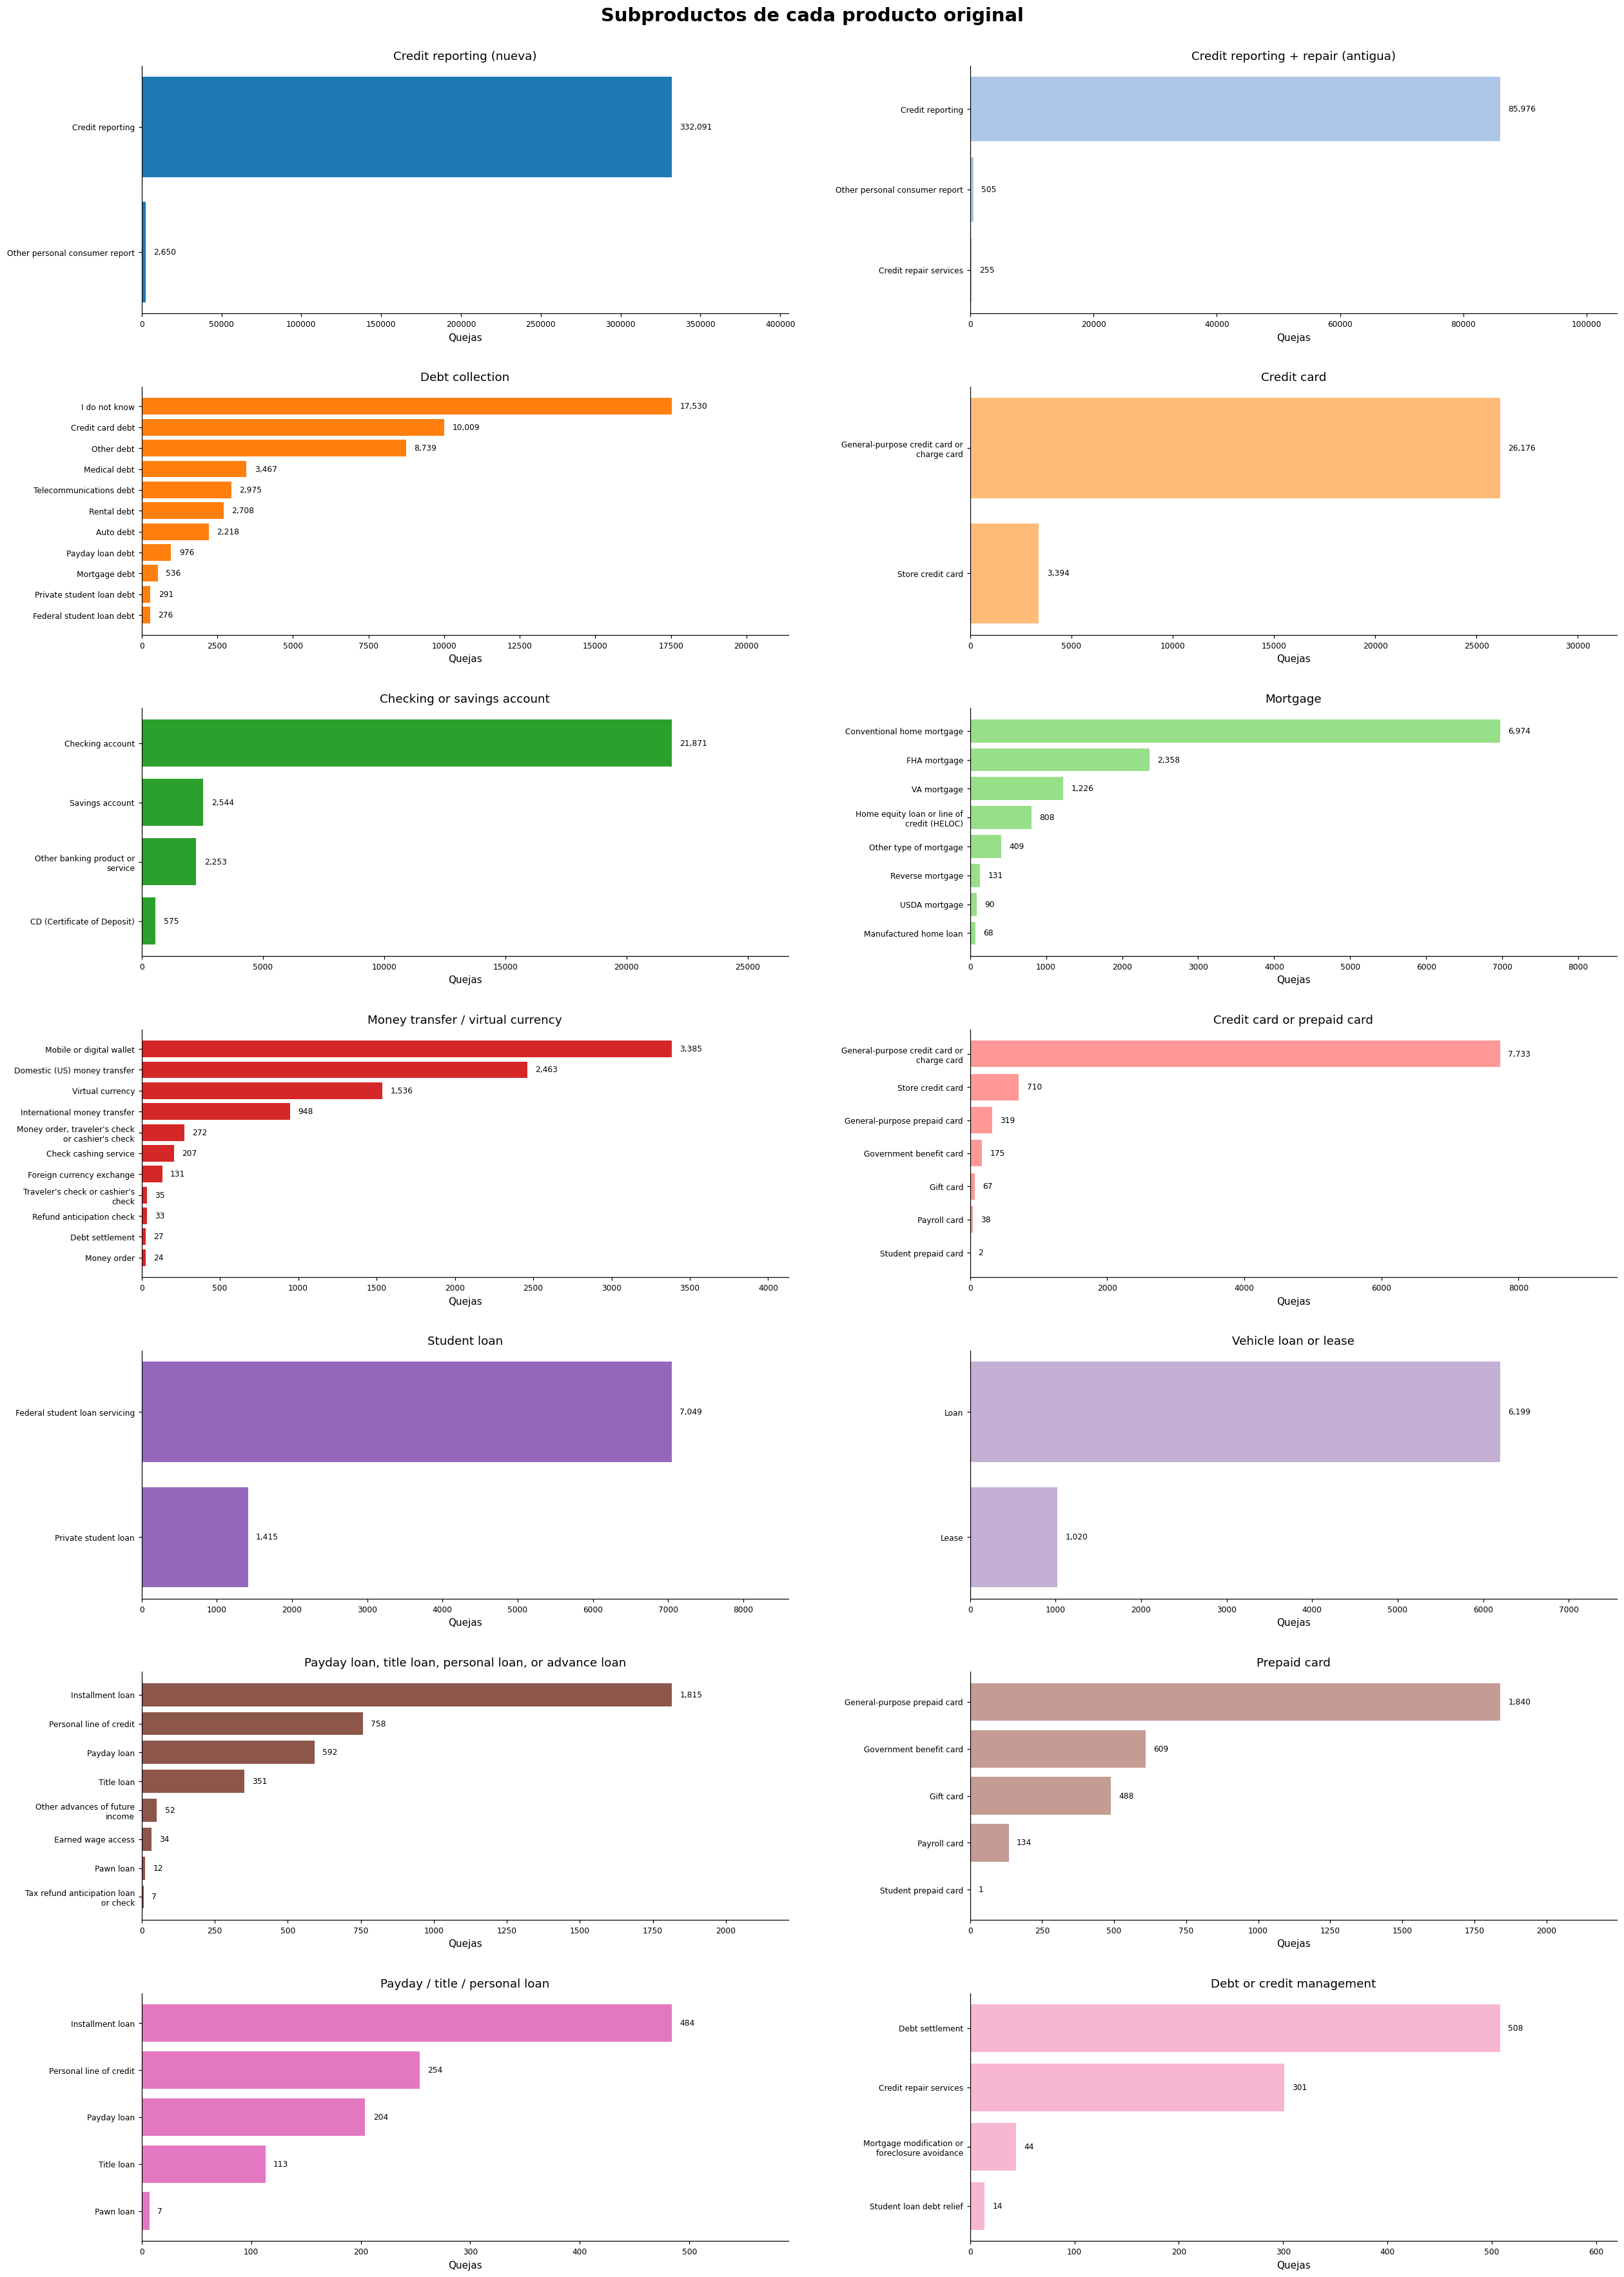

In [5]:
fig, axes = plt.subplots(7, 2, figsize=(23, 32))
for ax, product in zip(axes.flat, products.index):
    counts = df.loc[df["Product"].eq(product), "Sub-product"].value_counts().sort_values()
    ax.barh([fill(sub, 30) for sub in counts.index], counts.values, color=product_colors[product])
    for i, count in enumerate(counts):
        ax.text(count + counts.max()*.015, i, f"{count:,}", va="center", fontsize=8)
    ax.set(title=fill(short[product], 55), xlabel="Quejas", xlim=(0, counts.max()*1.22))
    ax.tick_params(axis="y", labelsize=8)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Subproductos de cada producto original", fontsize=19, fontweight="bold", y=1.002)
fig.tight_layout(h_pad=3.0, w_pad=4.0)
plt.show()

## 5. Taxonomía

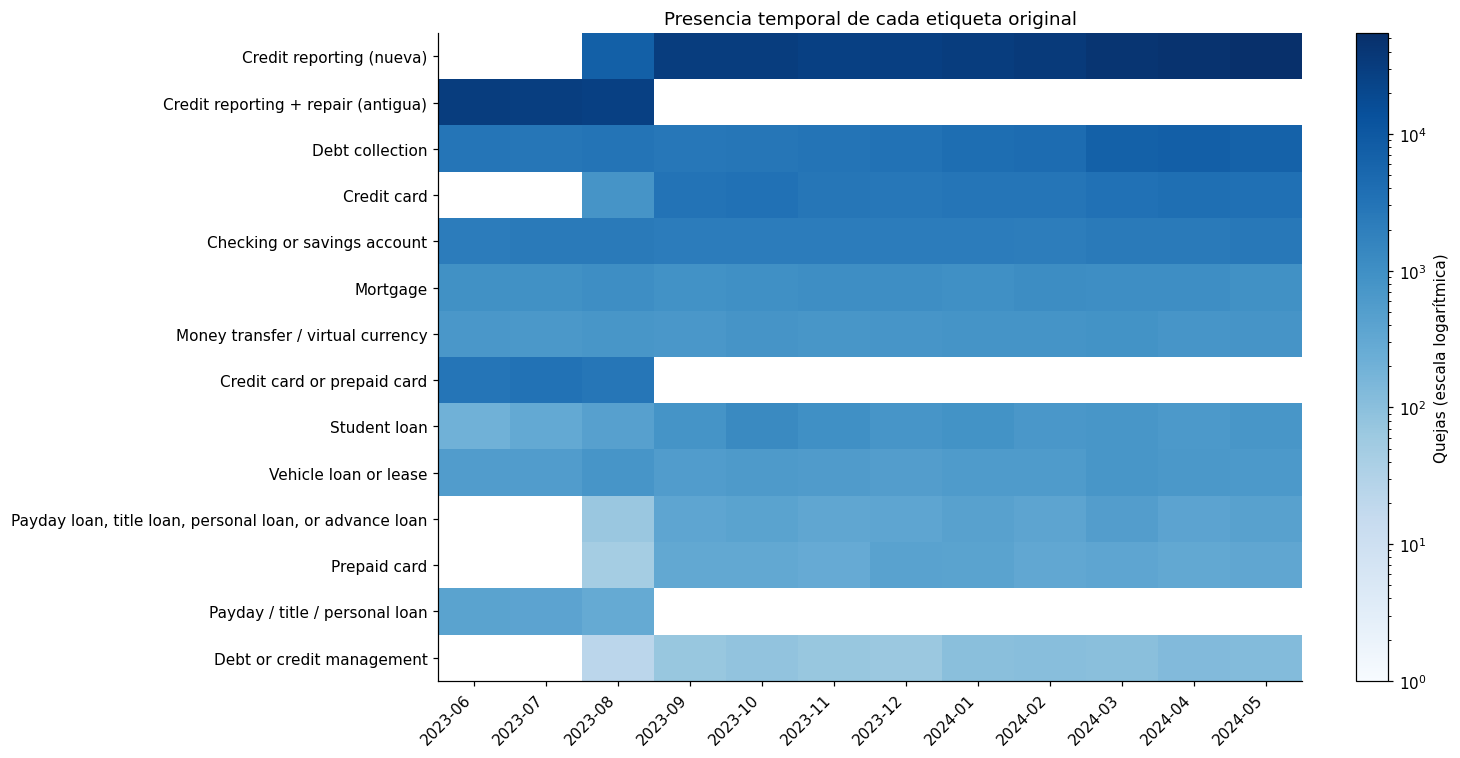

,Primera_fecha,Ultima_fecha
Product,,
"Payday loan, title loan, or personal loan",2023-06-01,2023-08-24
"Credit reporting, credit repair services, or other personal consumer reports",2023-06-01,2023-08-25
Credit card or prepaid card,2023-06-01,2023-08-25
Debt collection,2023-06-01,2024-05-31
Checking or savings account,2023-06-01,2024-05-31
Mortgage,2023-06-01,2024-05-31
"Money transfer, virtual currency, or money service",2023-06-01,2024-05-31
Student loan,2023-06-01,2024-05-31
Vehicle loan or lease,2023-06-01,2024-05-31


In [6]:
matrix = monthly.loc[:, products.index].T
fig, ax = plt.subplots(figsize=(14, 7))
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("white")
image = ax.imshow(np.ma.masked_equal(matrix.to_numpy(), 0), aspect="auto", cmap=cmap,
                  norm=LogNorm(vmin=1, vmax=matrix.to_numpy().max()))
ax.set_yticks(range(len(matrix)), [short[p] for p in matrix.index])
ax.set_xticks(range(len(monthly)), monthly.index, rotation=45, ha="right")
ax.set_title("Presencia temporal de cada etiqueta original")
fig.colorbar(image, ax=ax, label="Quejas (escala logarítmica)")
plt.tight_layout(); plt.show()
display(product_table[["Primera_fecha", "Ultima_fecha"]].sort_values(["Primera_fecha", "Ultima_fecha"]))

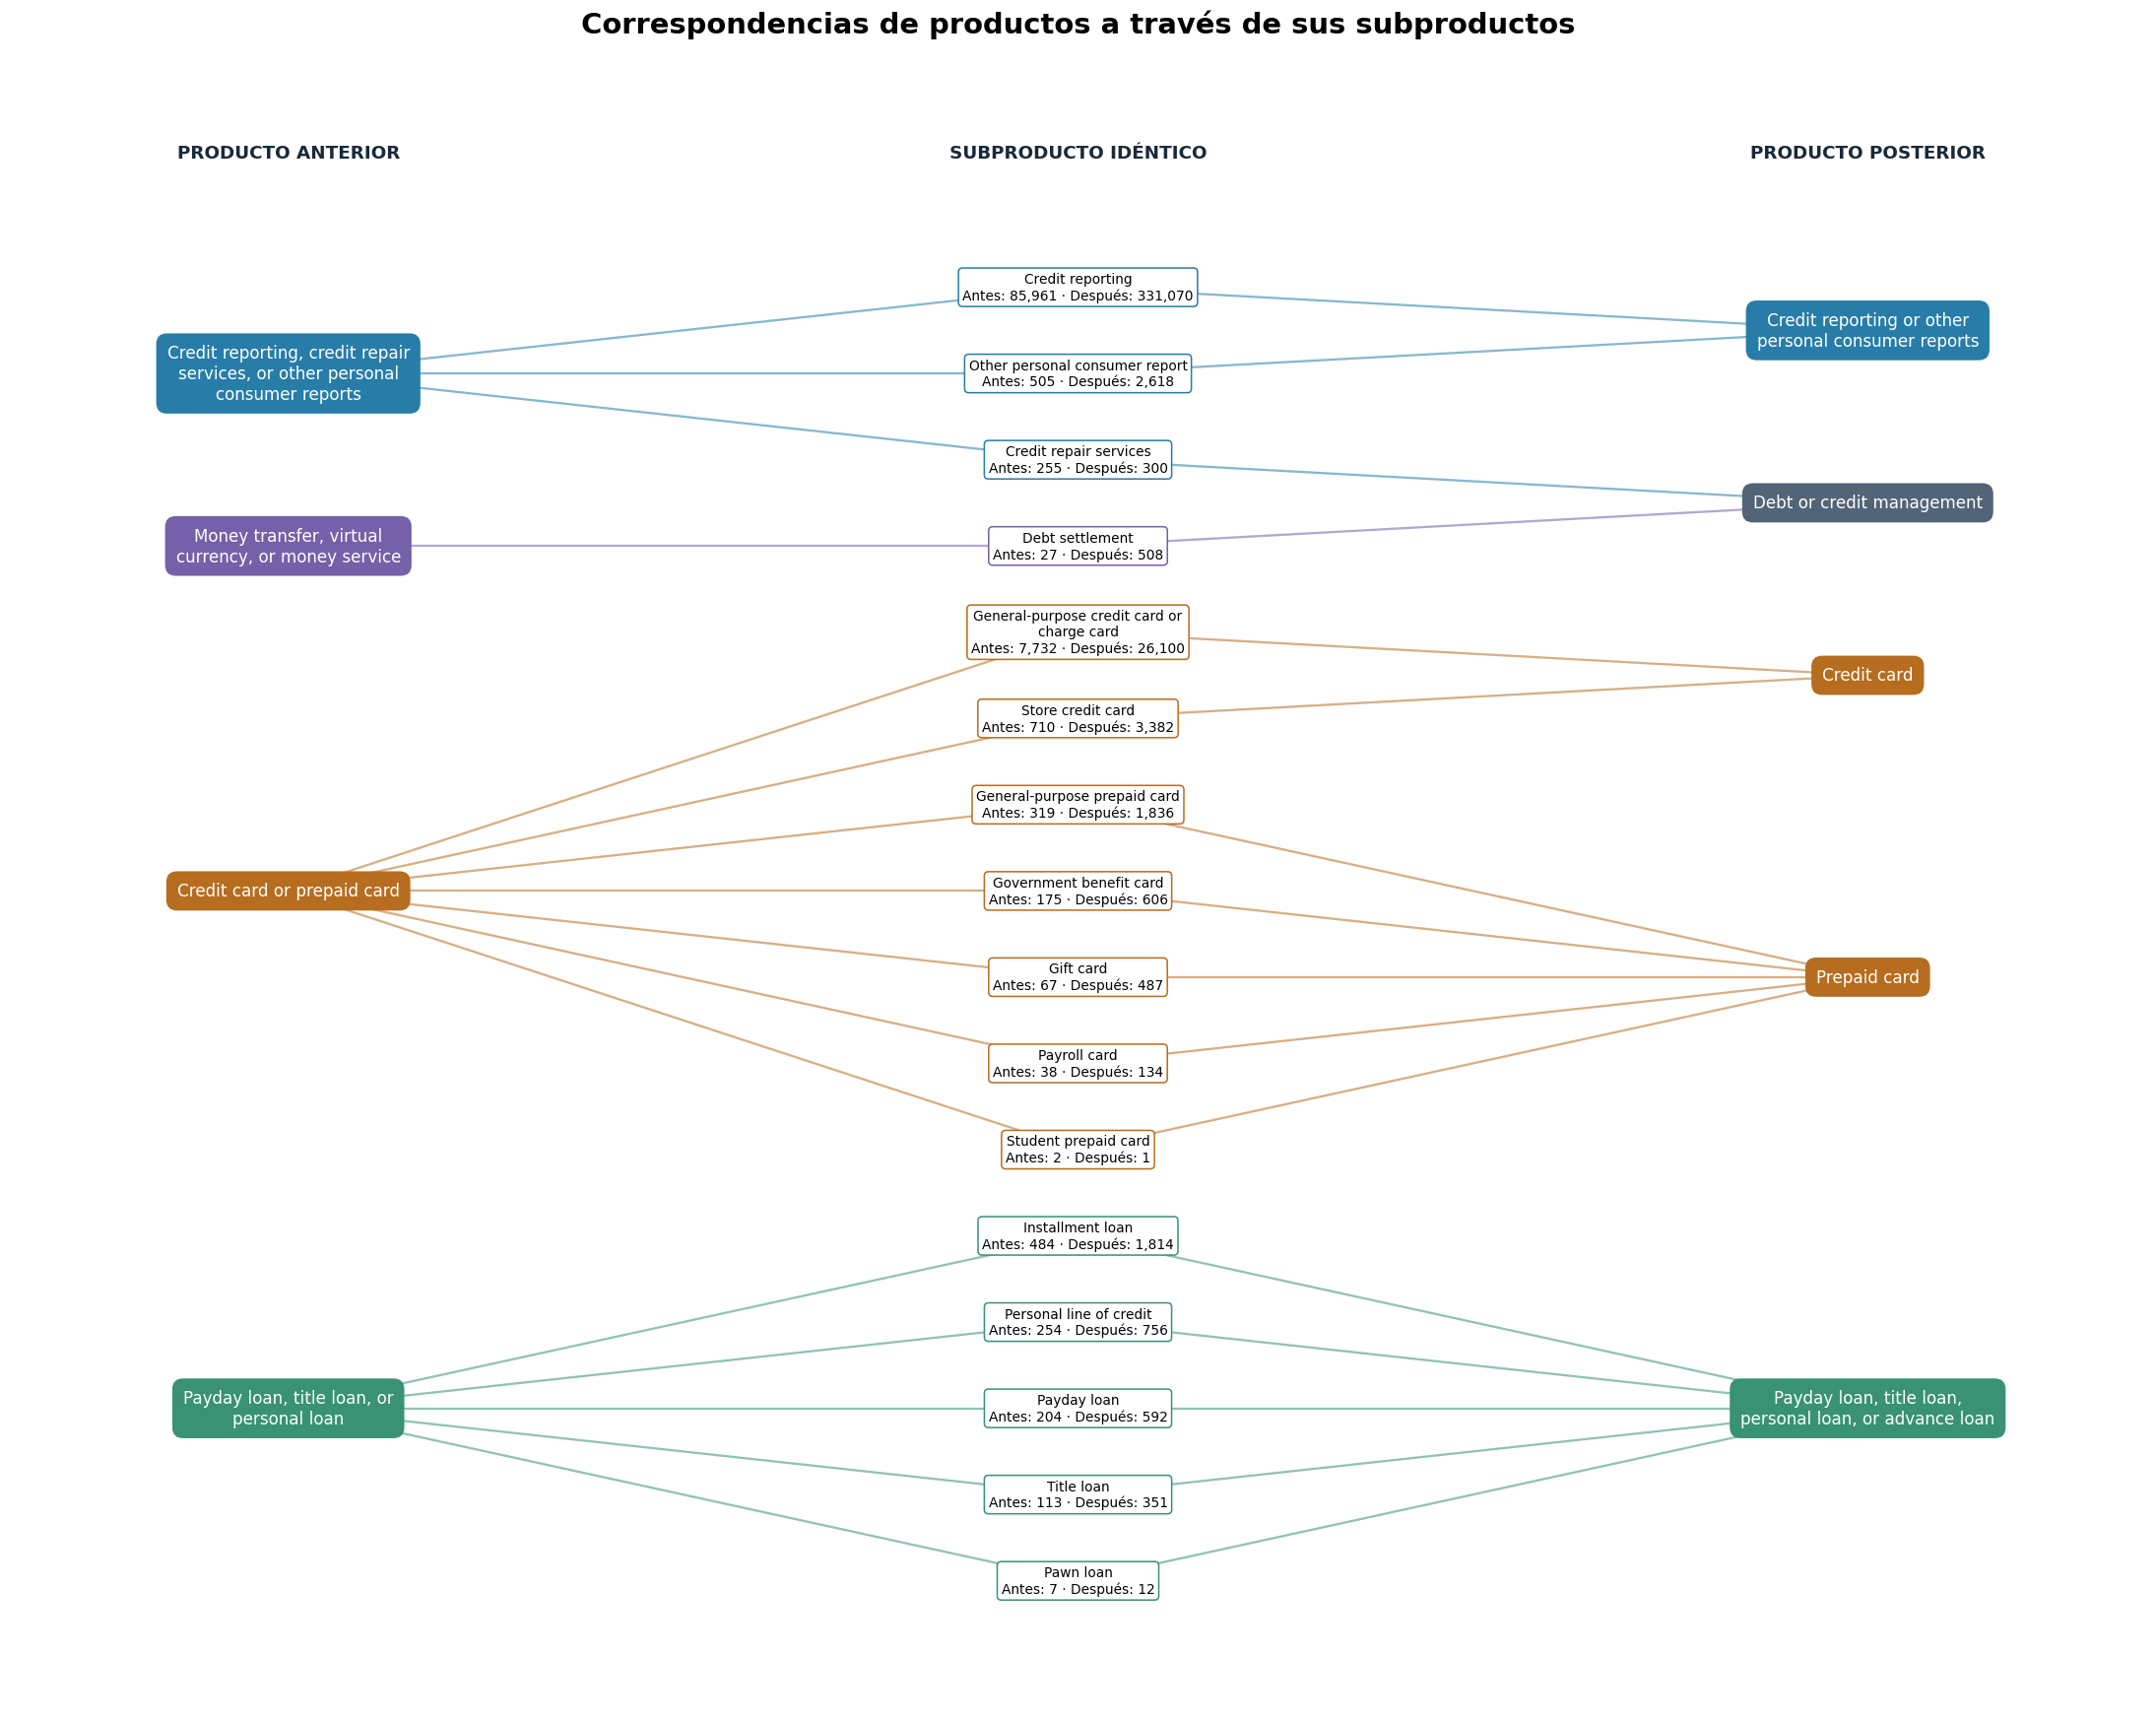

In [7]:
transition = pd.Timestamp("2023-08-25")
before = df.loc[df["date"] < transition]
after = df.loc[df["date"] > transition]
dates_by_product = df.groupby("Product")["date"].agg(["min", "max"])
discontinued = dates_by_product.index[dates_by_product["max"] <= transition].tolist()
introduced = dates_by_product.index[dates_by_product["min"] >= transition].tolist()

# Solo coincidencias exactas de Sub-product; no se recodifican nombres.
before_pairs = before.groupby(["Product", "Sub-product"]).size()
after_pairs = after.groupby(["Sub-product", "Product"]).size()
# Incluir también traslados desde productos que siguen existiendo.
changed_pairs = []
for old_product, subproduct in before_pairs.index:
    if subproduct in after_pairs.index.get_level_values(0):
        destinations = after_pairs.loc[subproduct].index
        if any(destination != old_product for destination in destinations):
            changed_pairs.append((old_product, subproduct))
before_pairs = before_pairs.loc[changed_pairs]
matches = []
for (old_product, subproduct), count_before in before_pairs.items():
    candidates = after_pairs.loc[subproduct] if subproduct in after_pairs.index.get_level_values(0) else pd.Series(dtype=int)
    if candidates.empty:
        matches.append({"Producto anterior": old_product, "Subproducto": subproduct,
                        "Producto posterior": None, "Quejas antes": int(count_before),
                        "Quejas después": 0, "Destinos candidatos": 0})
    else:
        for new_product, count_after in candidates.items():
            matches.append({"Producto anterior": old_product, "Subproducto": subproduct,
                            "Producto posterior": new_product, "Quejas antes": int(count_before),
                            "Quejas después": int(count_after), "Destinos candidatos": len(candidates)})
matches = pd.DataFrame(matches)
# Propuesta de sustitución por (producto anterior, subproducto).
assert matches["Destinos candidatos"].eq(1).all(), "Hay correspondencias ambiguas."
product_mapping = matches.set_index(["Producto anterior", "Subproducto"])["Producto posterior"]
assert product_mapping.index.is_unique
discontinued_pairs = pd.MultiIndex.from_frame(
    df.loc[df["Product"].isin(discontinued), ["Product", "Sub-product"]].drop_duplicates())
assert discontinued_pairs.isin(product_mapping.index).all(), "Faltan subproductos discontinuados por cubrir."
# Se conserva df con sus etiquetas originales para mostrar la evidencia del cambio.

# Para leer el diagrama, agrupar cada producto previo y sus destinos.
old_order = ["Credit reporting, credit repair services, or other personal consumer reports",
             "Money transfer, virtual currency, or money service",
             "Credit card or prepaid card", "Payday loan, title loan, or personal loan"]
matches["_order"] = pd.Categorical(matches["Producto anterior"], categories=old_order, ordered=True)
matches = matches.sort_values(["_order", "Producto posterior", "Quejas antes"],
                             ascending=[True, True, False]).drop(columns="_order").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(20, 16))
height = len(matches)
ys = {i: height - 1 - i for i in matches.index}
palette = dict(zip(old_order, ["#277da8", "#7560aa", "#b66d20", "#389273"]))
ax.set(xlim=(0, 1), ylim=(-1.5, height+1.2))
ax.axis("off")
left_x, middle_x, right_x = .13, .50, .87
for old, group in matches.groupby("Producto anterior", sort=False, observed=True):
    center = np.mean([ys[i] for i in group.index])
    ax.text(left_x, center, fill(old, 31), ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=.65", facecolor=palette[old], edgecolor="none"), color="white", zorder=4)
for new_product, group in matches.dropna(subset=["Producto posterior"]).groupby("Producto posterior", sort=False):
    center = np.mean([ys[i] for i in group.index])
    color = palette[group.iloc[0]["Producto anterior"]] if group["Producto anterior"].nunique() == 1 else "#526477"
    ax.text(right_x, center, fill(new_product, 30), ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=.65", facecolor=color, edgecolor="none"), color="white", zorder=4)
for i, row in matches.iterrows():
    color = palette[row["Producto anterior"]]
    old_center = np.mean([ys[j] for j in matches.index[matches["Producto anterior"].eq(row["Producto anterior"])]])
    ax.plot([left_x, middle_x], [old_center, ys[i]], color=color, alpha=.55, lw=1.5, zorder=1)
    if pd.notna(row["Producto posterior"]):
        new_center = np.mean([ys[j] for j in matches.index[matches["Producto posterior"].eq(row["Producto posterior"])]])
        ax.plot([middle_x, right_x], [ys[i], new_center], color=color, alpha=.55, lw=1.5, zorder=1)
    label = fill(row["Subproducto"], 36) + f"\nAntes: {row['Quejas antes']:,} · Después: {row['Quejas después']:,}"
    ax.text(middle_x, ys[i], label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=.3", facecolor="white", edgecolor=color), zorder=3)
for x, label in [(left_x, "PRODUCTO ANTERIOR"), (middle_x, "SUBPRODUCTO IDÉNTICO"), (right_x, "PRODUCTO POSTERIOR")]:
    ax.text(x, height+.5, label, ha="center", fontsize=12, fontweight="bold", color="#182a3a")
fig.suptitle("Correspondencias de productos a través de sus subproductos", fontsize=19, fontweight="bold", y=.99)
fig.tight_layout(rect=[0, 0, 1, .975])
plt.show()

## 6. Normalización de textos

In [8]:
def duplicate_profile(column):
    groups = df.groupby(column).agg(rows=("Product", "size"), labels=("Product", "nunique"), months=("month", "nunique"))
    repeated = groups[groups.rows > 1]
    conflicts = repeated[repeated.labels > 1]
    stats = {
        "unique_texts": len(groups), "extra_duplicate_rows": int((repeated.rows-1).sum()),
    }
    return stats

exact_duplicates = duplicate_profile("text_hash")
normalized_duplicates = duplicate_profile("normalized_hash")
names = {"unique_texts": "Textos distintos", "extra_duplicate_rows": "Filas adicionales repetidas",
        }
duplicate_comparison = pd.DataFrame({"Texto original": exact_duplicates, "Texto normalizado": normalized_duplicates})
duplicate_comparison["Cambio tras normalizar"] = duplicate_comparison["Texto normalizado"] - duplicate_comparison["Texto original"]
display(duplicate_comparison.rename(index=names))

,Texto original,Texto normalizado,Cambio tras normalizar
Textos distintos,377462,364650,-12812
Filas adicionales repetidas,205027,217839,12812


## 7. Empresas

In [9]:
company_counts = pd.Series(dict(values["Company"].most_common()), name="Quejas")
company_table = company_counts.to_frame()
company_table["% del total de filas"] = 100 * company_table["Quejas"] / n
company_table.index.name = "Company"
display(company_table.head(10).round({"% del total de filas": 2}))

,Quejas,% del total de filas
Company,,
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",136974,23.52
"EQUIFAX, INC.",135152,23.20
Experian Information Solutions Inc.,132531,22.75
JPMORGAN CHASE & CO.,9423,1.62
CAPITAL ONE FINANCIAL CORPORATION,9304,1.60
"BANK OF AMERICA, NATIONAL ASSOCIATION",7665,1.32
WELLS FARGO & COMPANY,7453,1.28
"CITIBANK, N.A.",5956,1.02
SYNCHRONY FINANCIAL,4556,0.78


### 7.1. Distribución de productos en las tres principales empresas y el resto agregado

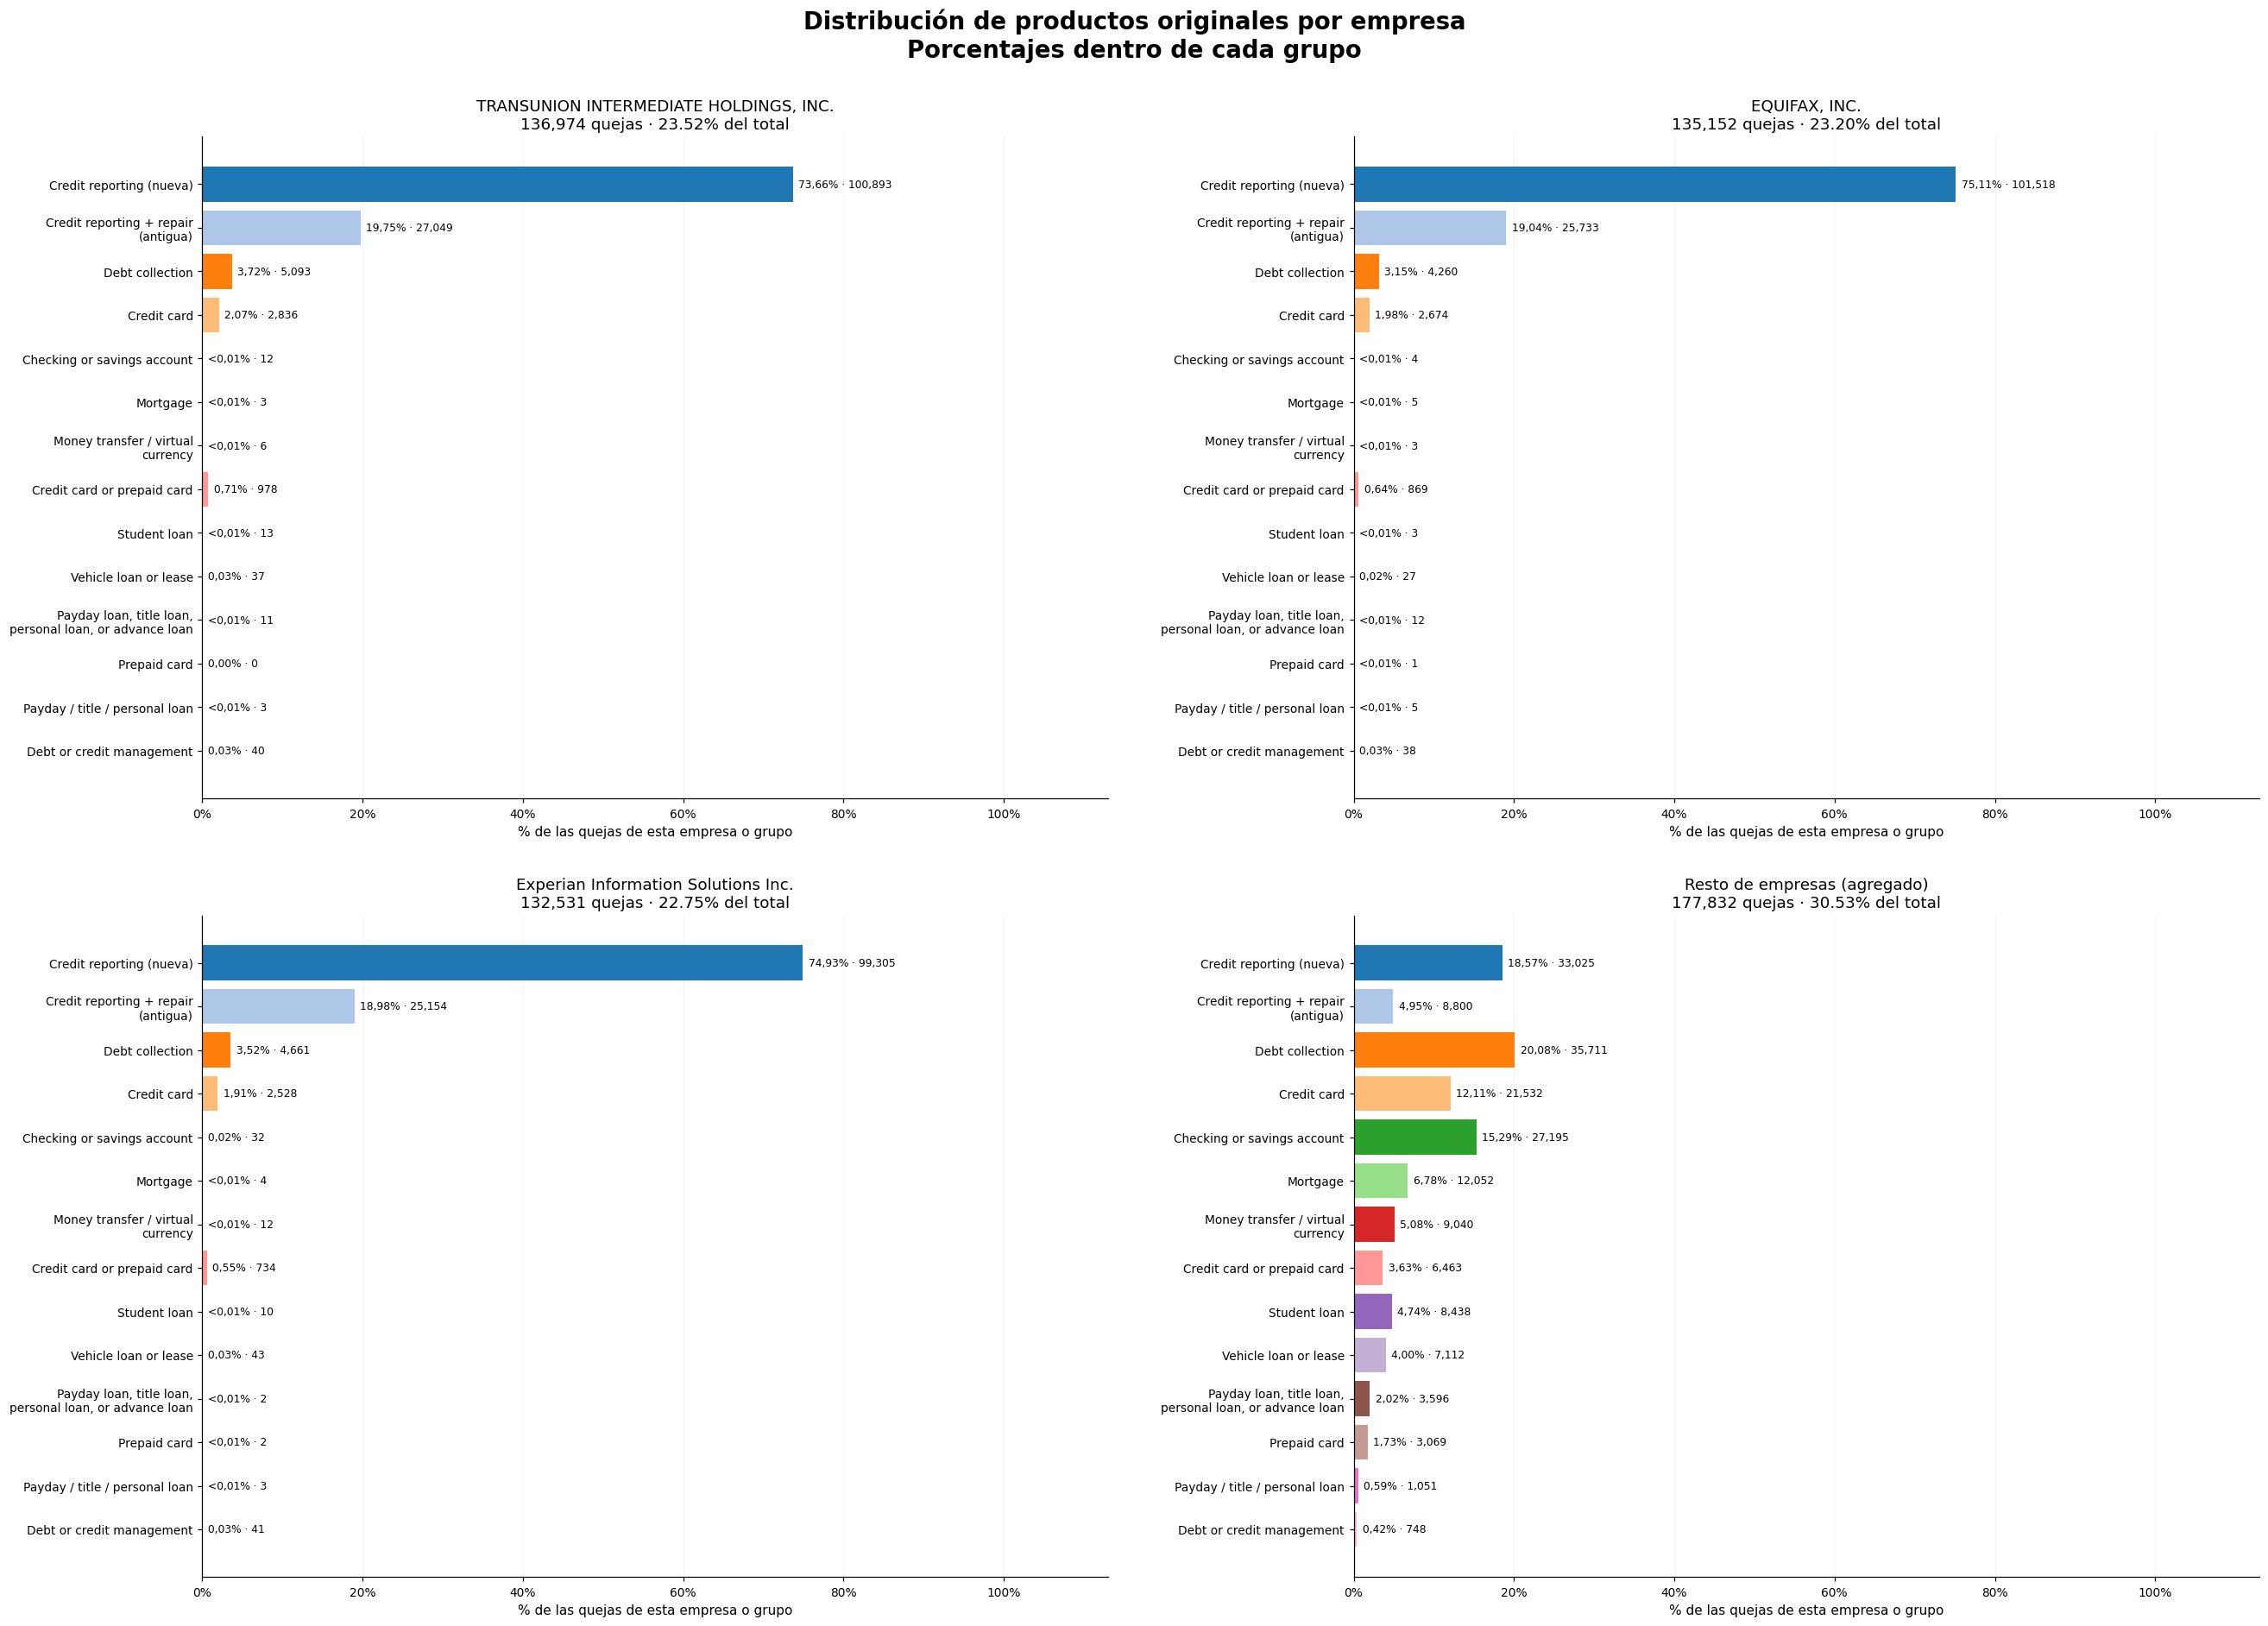

In [10]:
leading_companies = df["Company"].value_counts().head(3).index.tolist()
other_label = "Resto de empresas (agregado)"
company_groups = df["Company"].where(df["Company"].isin(leading_companies), other_label)
group_order = leading_companies + [other_label]
company_product_counts = pd.crosstab(company_groups, df["Product"]).reindex(
    index=group_order, columns=products.index, fill_value=0)
company_product_counts.index.name = "Empresa / grupo"
group_totals = company_product_counts.sum(axis=1)
company_product_pct = company_product_counts.div(group_totals, axis=0) * 100

assert company_product_counts.to_numpy().sum() == n
np.testing.assert_allclose(company_product_pct.sum(axis=1), 100)

company_group_summary = pd.DataFrame({
    "Quejas": group_totals,
    "% de todas las quejas": 100 * group_totals / n,
})

fig, axes = plt.subplots(2, 2, figsize=(24, 17))
product_order = list(products.index[::-1])
for ax, group in zip(axes.flat, group_order):
    percentages = company_product_pct.loc[group, product_order]
    counts = company_product_counts.loc[group, product_order]
    ax.barh([fill(short[p], 31) for p in product_order], percentages.to_numpy(),
            color=[product_colors[p] for p in product_order])
    for position, product in enumerate(product_order):
        pct, count = percentages[product], counts[product]
        pct_label = "<0,01%" if 0 < pct < .01 else f"{pct:.2f}%".replace(".", ",")
        ax.text(pct + .7, position, f"{pct_label} · {count:,}", va="center", fontsize=8)
    ax.set(title=fill(group, 48) + f"\n{group_totals[group]:,} quejas · {100*group_totals[group]/n:.2f}% del total",
           xlabel="% de las quejas de esta empresa o grupo", xlim=(0, 113))
    ax.set_xticks([0, 20, 40, 60, 80, 100], ["0%", "20%", "40%", "60%", "80%", "100%"])
    ax.tick_params(axis="y", labelsize=9)
    ax.tick_params(axis="x", labelsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Distribución de productos originales por empresa\nPorcentajes dentro de cada grupo",
             fontsize=18, fontweight="bold", y=1.005)
fig.tight_layout(h_pad=3, w_pad=4)
plt.show()

## 8. Reglas de negocio

In [11]:
if str(ROOT / "EDA") not in sys.path:
    sys.path.insert(0, str(ROOT / "EDA"))
from reglas_negocio import aplicar_reglas_negocio

cierre = aplicar_reglas_negocio(df)
df_armonizado = cierre["datos"]
resumen_cierre = cierre["resumen"]
display(pd.Series({
    "Filas antes": resumen_cierre["rows_before"],
    "Filas después": resumen_cierre["rows_after"],
    "Productos antes": resumen_cierre["products_before"],
    "Productos después": resumen_cierre["products_after"],
    "Reglas aplicadas": resumen_cierre["rules_observed"],
    "Filas recodificadas": resumen_cierre["rows_recoded"],
    "Filas del 25/08/2023": resumen_cierre["transition_day_rows"],
    "Filas recodificadas del 25/08/2023": resumen_cierre["transition_day_rows_recoded"],
    "Textos normalizados distintos": resumen_cierre["unique_normalized_texts"],
    "Filas eliminadas": 0,
}, name="Resultado").to_frame())

,Resultado
Filas antes,582489
Filas después,582489
Productos antes,14
Productos después,11
Reglas aplicadas,16
Filas recodificadas,96869
Filas del 25/08/2023,1410
Filas recodificadas del 25/08/2023,16
Textos normalizados distintos,364650
Filas eliminadas,0


### 8.1. Armonización de productos y cobertura del día de transición

,Producto original,Subproducto,Producto armonizado,Filas sustituidas,Antes del 25/08,El 25/08,Después del 25/08
0,"Credit reporting, credit repair services, or o...",Credit reporting,Credit reporting or other personal consumer re...,85976,85961,15,0
1,"Credit reporting, credit repair services, or o...",Other personal consumer report,Credit reporting or other personal consumer re...,505,505,0,0
2,"Credit reporting, credit repair services, or o...",Credit repair services,Debt or credit management,255,255,0,0
3,Credit card or prepaid card,General-purpose credit card or charge card,Credit card,7733,7732,1,0
4,Credit card or prepaid card,Store credit card,Credit card,710,710,0,0
5,Credit card or prepaid card,General-purpose prepaid card,Prepaid card,319,319,0,0
6,Credit card or prepaid card,Government benefit card,Prepaid card,175,175,0,0
7,Credit card or prepaid card,Gift card,Prepaid card,67,67,0,0
8,Credit card or prepaid card,Payroll card,Prepaid card,38,38,0,0
9,Credit card or prepaid card,Student prepaid card,Prepaid card,2,2,0,0


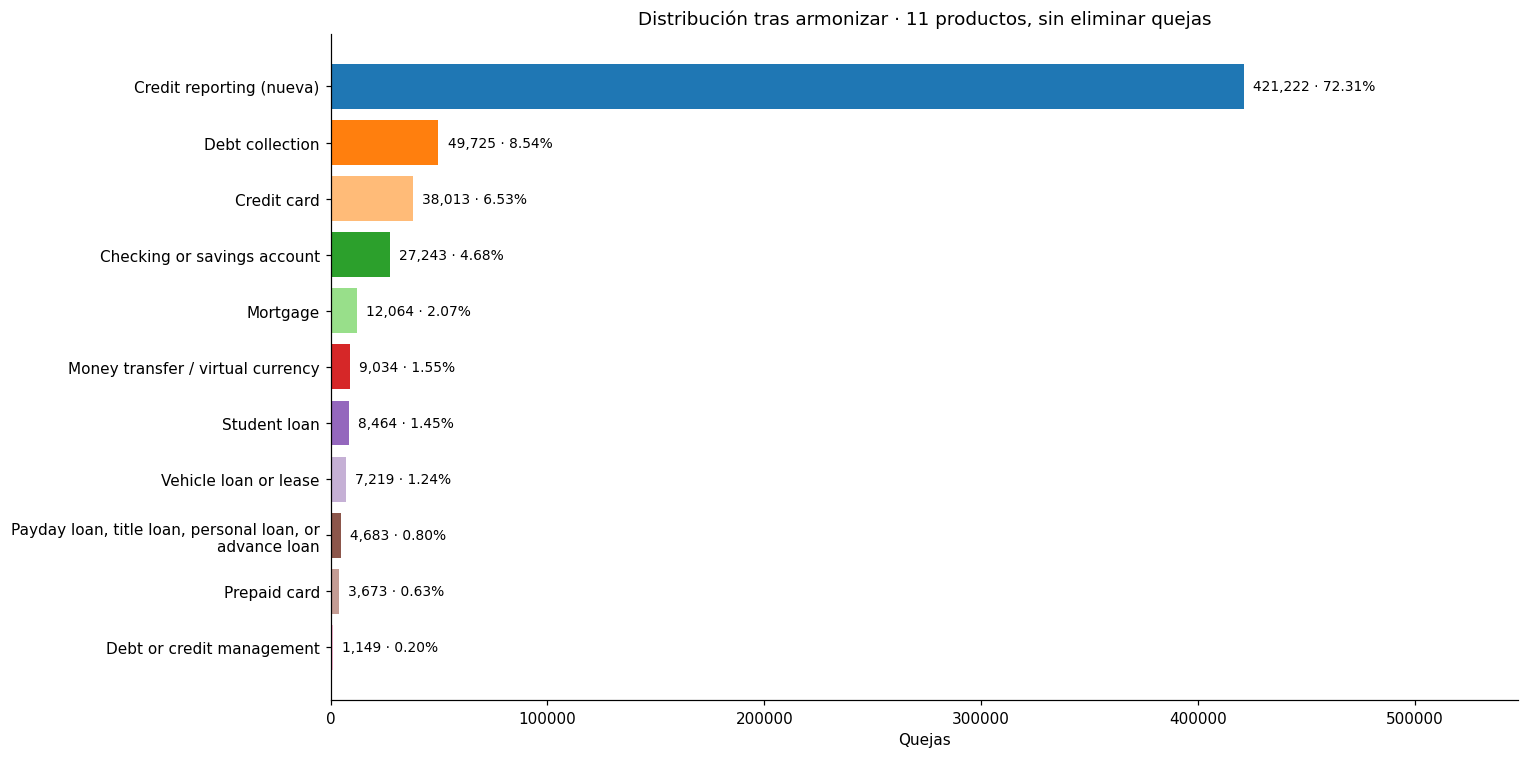

In [12]:
display(cierre["auditoria_taxonomia"])
fig, ax = plt.subplots(figsize=(14, 7))
distribution = cierre["distribucion_productos"].iloc[::-1]
ax.barh([fill(short[p], 42) for p in distribution.index], distribution.Quejas,
        color=[product_colors[p] for p in distribution.index])
for i, (_, row) in enumerate(distribution.iterrows()):
    ax.text(row.Quejas + distribution.Quejas.max()*.01, i,
            f"{int(row.Quejas):,} · {row['% del total']:.2f}%", va="center", fontsize=9)
ax.set(title="Distribución tras armonizar · 11 productos, sin eliminar quejas",
       xlabel="Quejas", xlim=(0, distribution.Quejas.max()*1.3))
plt.tight_layout(); plt.show()